In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Singlish Dataset.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

sns.set_theme(style="whitegrid")

print("Dataset loaded:", df.shape)


Dataset loaded: (7832, 2)


,Number of Comments
Sentiment,
Pos,4263
Neg,1853
Neu,1716


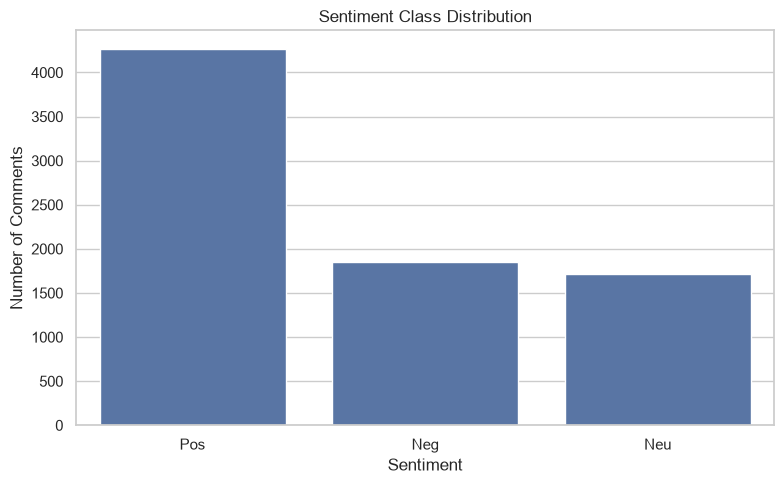

In [2]:

sentiment_counts = df["Sentiment"].value_counts()

display(sentiment_counts.to_frame(name="Number of Comments"))

plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df,
    x="Sentiment",
    order=["Pos", "Neg", "Neu"]
)

ax.set_title("Sentiment Class Distribution")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Comments")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "sentiment_distribution_notebook.png", dpi=300)
plt.show()


,Percentage (%)
Sentiment,
Pos,54.43
Neg,23.66
Neu,21.91


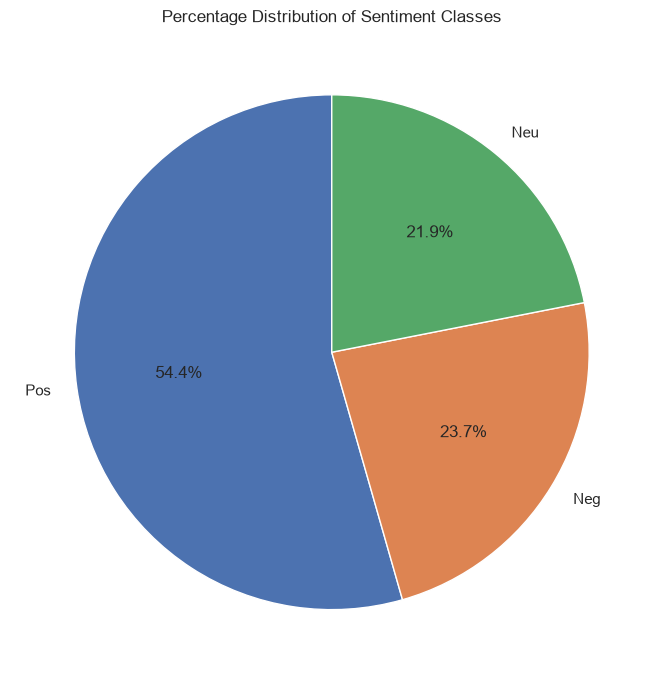

In [3]:

sentiment_percentages = (
    df["Sentiment"].value_counts(normalize=True) * 100
).round(2)

display(sentiment_percentages.to_frame(name="Percentage (%)"))

plt.figure(figsize=(7, 7))
plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage Distribution of Sentiment Classes")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "sentiment_percentage_notebook.png", dpi=300)
plt.show()


,Word Count
count,7832.000000
mean,9.540986
std,5.917869
min,1.000000
25%,5.000000
50%,8.000000
75%,12.000000
max,43.000000


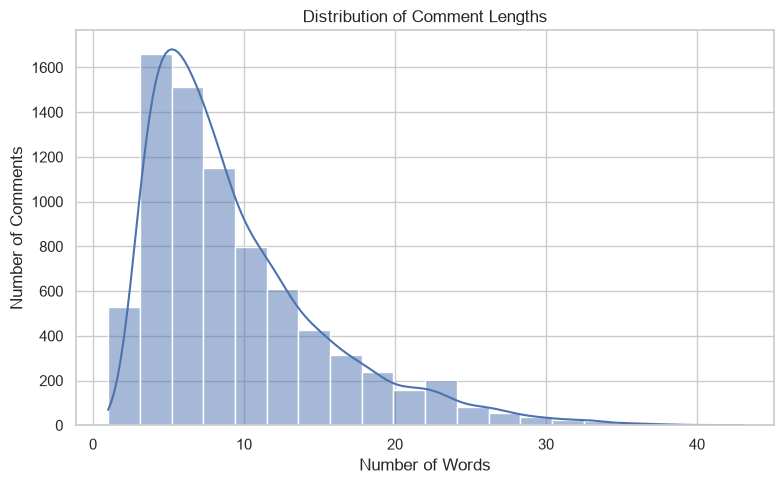

In [4]:

df["Comment_Length"] = df["Comments"].astype(str).str.split().str.len()

display(df["Comment_Length"].describe().to_frame(name="Word Count"))

plt.figure(figsize=(8, 5))
sns.histplot(df["Comment_Length"], bins=20, kde=True)

plt.title("Distribution of Comment Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Comments")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "comment_length_distribution.png", dpi=300)
plt.show()


,count,mean,median
Sentiment,,,
Neg,1853,10.72,9.0
Neu,1716,9.25,8.0
Pos,4263,9.14,7.0


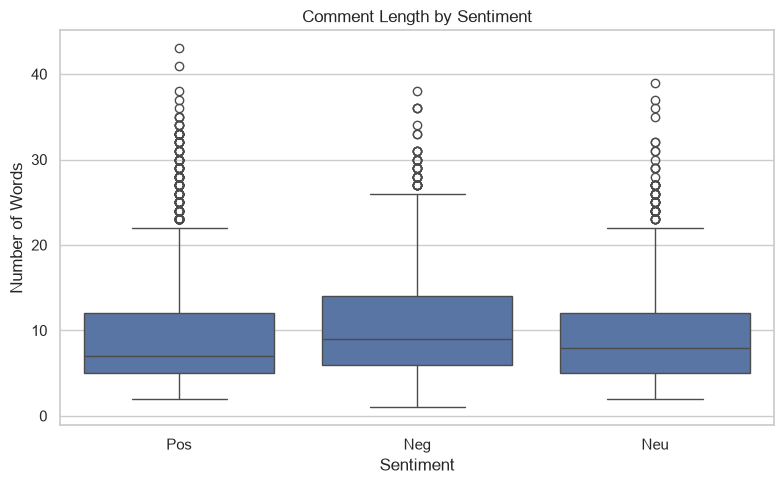

In [5]:

display(
    df.groupby("Sentiment")["Comment_Length"]
    .agg(["count", "mean", "median"])
    .round(2)
)

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Sentiment",
    y="Comment_Length",
    order=["Pos", "Neg", "Neu"]
)

plt.title("Comment Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "comment_length_by_sentiment_notebook.png", dpi=300)
plt.show()
